# Regional plus local: one signal shared by every station and one signal per station

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/jejjohnson/pyrox/blob/main/docs/notebooks/ssm/ssm_shared_plus_site.ipynb)

[Example 2](ssm_hierarchical_sites.ipynb) gave every station its own weather anomaly and let the stations share only their hyperparameters. However, stations a few tens of kilometres apart see the same weather systems pass over them, so a large part of their anomalies is one regional signal. Here we split each station's anomaly into a slow regional part that every station shares and a faster local part of its own. The regional part couples the stations, so they can no longer be fitted one at a time. We put all of them into one state-space model on the merged grid of the days that any station reported, with `SharedPlusSiteMarkovGP`, and the Kalman filter integrates out the regional path and every local path at once. A station's gaps are then filled by its neighbours, and the posterior splits each record into its regional and local parts.

**pyrox-ssm capability shown:** `SharedPlusSiteMarkovGP.from_sites`, which merges ragged station records onto one grid with a `(T, N_Ω)` mask, `log_marginal`, which is the exact Kalman log marginal of the observed (day, station) pairs under one block-diagonal linear-Gaussian SSM, and `decompose` together with `as_lgssm(...).smooth(...)`, which give the posterior of the regional and the local parts. **Cost:** every log-density evaluation is one Kalman filter pass over the $T$ merged days with a state of dimension $D_x = D_g + N_\Omega D_h$, so $\mathcal{O}(T D_x^3)$, cubic in the number of stations $N_\Omega$. We measure the wall-clock times of the fits, of the predictions and of one gradient for growing networks in section 8.

**What you'll learn:**

1. How to write a regional-plus-local model for a station network as a plain NumPyro function, with `from_sites` for the merged grid and `log_marginal` as one factor.
2. How to recover the regional signal and each station's local signal, with their uncertainty, from the posterior averaged over the NUTS draws.
3. How the regional signal lets the network predict a station through its outages and after it stops, compared with Example 2's model, in which the stations do not share their anomalies.

The single-station model, its priors and the Kalman marginal likelihood are explained in [Example 1](ssm_one_site.ipynb), and the ragged records and `pad_sites` in [Example 2](ssm_hierarchical_sites.ipynb). We reuse both here without deriving them again.

## Background

The network is again a set $\Omega_y$ of $N_\Omega \equiv N_{\Omega_y}$ stations, indexed by $n = 1, \ldots, N_\Omega$, and station $n$ reported on the days $\mathcal{T}_{y,n}$. We work with daily mean temperature anomalies (°C), each station's record minus its climatology, which we take as known (it is Example 2's $c_n + \mu(t)$). The anomaly that Example 2 modelled as one independent GP $f_n$ per station is now a regional anomaly $g$, shared by every station, plus a local anomaly $h_n$,

$$y_n(t) = g(t) + h_n(t) + \varepsilon_n(t)$$

$$g \sim \mathcal{GP}(0, k_\text{Matérn-3/2}(t, t'; \sigma_g^2, \ell_g))$$

$$h_n \sim \mathcal{GP}(0, k_\text{Matérn-3/2}(t, t'; \sigma_h^2, \ell_h))$$

$$\varepsilon_n(t) \sim \mathcal{N}(0, \sigma_\varepsilon^2)$$

with $g$, $h_1, \ldots, h_{N_\Omega}$ and the noise all independent. The kernel variances $\sigma_g^2$ and $\sigma_h^2$ (°C²), the lengthscales $\ell_g$ and $\ell_h$ (days) and the noise variance $\sigma_\varepsilon^2$ (°C²) are all in $\mathbb{R}_{>0}$, and the local kernel is pooled over the stations, so $\boldsymbol{\theta} = (\sigma_g^2, \ell_g, \sigma_h^2, \ell_h, \sigma_\varepsilon^2) \in \mathbb{R}^{5}$ are the five parameters that NUTS infers. We expect the regional signal to be the slower and the larger of the two, but the model does not impose it.

Because $g$ is shared, the stations are no longer independent given $\boldsymbol{\theta}$, and Example 2's one filter per station does not apply. Instead we merge the station days into one grid, $\mathcal{T}_y = \bigcup_n \mathcal{T}_{y,n} = \{t_1 < \ldots < t_T\}$ with $T \equiv N_{\mathcal{T}_y}$, on which the day index $k$ is the same for every station. So station $n$'s anomaly on day $t_k$ is $y_{n,k}$, observed when the mask $o_{n,k} \in \{0, 1\}$ is 1. The state stacks the Matérn-3/2 states of $g$ and of every $h_n$,

$$\mathbf{x}_k = (\mathbf{x}_{g,k}, \mathbf{x}_{h,1,k}, \ldots, \mathbf{x}_{h,N_\Omega,k}) \in \mathbb{R}^{D_x}$$

where $\mathbf{x}_{g,k}, \mathbf{x}_{h,n,k} \in \mathbb{R}^{2}$, so $D_g = D_h = 2$ and $D_x = D_g + N_\Omega D_h$. The independent processes give block-diagonal transitions and model noise covariances,

$$\mathbf{F}_k = \mathrm{blockdiag}(\mathbf{F}_{g,k}, \mathbf{F}_{h,1,k}, \ldots, \mathbf{F}_{h,N_\Omega,k})$$

with $\mathbf{F}_k, \boldsymbol{\Sigma}_{\eta,k} \in \mathbb{R}^{D_x \times D_x}$ and each block the discretisation of its SDE over $\Delta t_k = t_k - t_{k-1}$ (Example 1), and $\boldsymbol{\Sigma}_{\eta,k}$ built in the same way. Station $n$ observes the sum of the regional block and its own block, so row $n$ of the measurement matrix $\mathbf{H} \in \mathbb{R}^{N_\Omega \times D_x}$ is $(\mathbf{H}_g, \mathbf{0}, \ldots, \mathbf{H}_h, \ldots, \mathbf{0})$, with $\mathbf{H}_g, \mathbf{H}_h \in \mathbb{R}^{1 \times 2}$ the Matérn-3/2 measurement rows and $\mathbf{H}_h$ in block $n$. On day $t_k$ only the stations $\mathcal{O}_k = \{n : o_{n,k} = 1\}$ reported, and the Kalman filter updates with those rows only. With $\mathbf{y}_{\mathcal{O}_k} \in \mathbb{R}^{N_{\mathcal{O}_k}}$ their anomalies and $\mathbf{H}_{\mathcal{O}_k} \in \mathbb{R}^{N_{\mathcal{O}_k} \times D_x}$ their rows of $\mathbf{H}$,

$$\log p(\mathbf{Y} \mid \boldsymbol{\theta}) = \sum_{k=1}^{T} \log \mathcal{N}(\mathbf{y}_{\mathcal{O}_k}; \mathbf{H}_{\mathcal{O}_k} \boldsymbol{\mu}_{x,k \mid k-1}, \mathbf{H}_{\mathcal{O}_k} \boldsymbol{\Sigma}_{x,k \mid k-1} \mathbf{H}_{\mathcal{O}_k}^\top + \sigma_\varepsilon^2 \mathbf{I}_{N_{\mathcal{O}_k}})$$

where $\mathbf{Y} \in \mathbb{R}^{T \times N_\Omega}$ holds the anomalies with one row per merged day and one column per station, and $\boldsymbol{\mu}_{x,k \mid k-1} \in \mathbb{R}^{D_x}$ and $\boldsymbol{\Sigma}_{x,k \mid k-1} \in \mathbb{R}^{D_x \times D_x}$ are the one-step-ahead moments of the joint state. This is the dense Gaussian of all the observed (day, station) pairs, computed in $\mathcal{O}(T D_x^3)$ instead of $\mathcal{O}((\sum_n N_n)^3)$, where $N_n \equiv \vert \mathcal{T}_{y,n} \vert$.

## Setup

We detect Colab and install `pyrox`, `pyrox-gp[colab]` (which pulls in `matplotlib` and `watermark`) and `pyrox-ssm` only when the notebook runs there.

In [1]:
import subprocess
import sys


try:
    import google.colab  # noqa: F401

    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    subprocess.run(
        [
            sys.executable,
            "-m",
            "pip",
            "install",
            "-q",
            "pyrox @ git+https://github.com/jejjohnson/pyrox@main#subdirectory=packages/pyrox",
            "pyrox-gp[colab] @ git+https://github.com/jejjohnson/pyrox@main#subdirectory=packages/pyrox-gp",
            "pyrox-ssm @ git+https://github.com/jejjohnson/pyrox@main#subdirectory=packages/pyrox-ssm",
        ],
        check=True,
    )

In [2]:
import warnings


warnings.filterwarnings("ignore", message=r".*IProgress.*")

import time

import einx
import jax
import jax.numpy as jnp
import jax.random as jr
import matplotlib.pyplot as plt
import numpy as np
import numpyro
import numpyro.distributions as dist
from jax.scipy.stats import multivariate_normal
from numpyro import handlers
from numpyro.infer import MCMC, NUTS, init_to_median
from pyrox_ssm import (
    MarkovGPPrior,
    MaternSDE,
    SharedPlusSiteMarkovGP,
    markov_gp_from_innovations,
    pad_sites,
)


# two CPU devices, so the two NUTS chains run in parallel
numpyro.set_host_device_count(2)
jax.config.update("jax_enable_x64", True)

In [3]:
import importlib.util


try:
    from IPython import get_ipython

    ipython = get_ipython()
except ImportError:
    ipython = None

if ipython is not None and importlib.util.find_spec("watermark") is not None:
    ipython.run_line_magic("load_ext", "watermark")
    ipython.run_line_magic(
        "watermark", "-v -m -p jax,equinox,numpyro,gaussx,pyrox,pyrox_ssm,matplotlib"
    )
else:
    print("watermark extension not installed; skipping reproducibility readout.")

Python implementation: CPython
Python version       : 3.13.12
IPython version      : 9.13.0

jax       : 0.10.2
equinox   : 0.13.8
numpyro   : 0.21.0
gaussx    : 0.6.15
pyrox     : 0.2.1
pyrox_ssm : 0.1.0
matplotlib: 3.10.9

Compiler    : Clang 21.1.4 
OS          : Linux
Release     : 6.8.0-1044-azure
Machine     : x86_64
Processor   : x86_64
CPU cores   : 16
Architecture: 64bit



## 1. A network that shares its weather

We simulate 135 days of a five-station network from the model itself, so that we know every true value. The regional anomaly has Example 1's 2 °C spread but decorrelates over about eight days, as a passing weather system would. Each station adds a local anomaly of 1 °C that decorrelates over about two days, and the sensor noise is again 0.5 °C. We simulate all the paths on every day, including days that no station reported, so that we can score the predictions later.

The stations report on their own schedules over the first 120 days, and days 120 to 134 are left for a forecast. Stations 1 and 2 cover the whole window, and station 2 has a 20-day logger outage from day 80, which falls in the coldest regional spell of the record. Station 3 is read by hand every second day from day 10 to day 110, station 4 starts on day 30 and misses another 30 % of its days, and station 5 stops after day 80. As in Example 2, every station also misses each day with probability 0.08, and we keep only the days a station reported.

In [4]:
# Shapes: N_Ω = 5 stations; N_days = 135 simulated days; D_g = D_h = 2

truth = {
    "regional_variance": 4.0,  # (2 °C)^2
    "regional_lengthscale": 8.0,  # days
    "local_variance": 1.0,  # (1 °C)^2
    "local_lengthscale": 2.0,  # days
    "noise_var": 0.25,  # (0.5 °C)^2
}
N_DAYS = 135
LAST_REPORT = 120  # stations report on days 0, …, 119; the rest is a forecast

# (first day, last day + 1, outage or None, extra dropout rate, reading interval)
schedule = [
    (0, 120, None, 0.0, 1),
    (0, 120, (80, 100), 0.0, 1),
    (10, 111, None, 0.0, 2),
    (30, 120, None, 0.3, 1),
    (0, 81, None, 0.0, 1),
]
n_stations = len(schedule)

# every simulated day, t = 0, …, 134
days = jnp.arange(N_DAYS, dtype=jnp.float64)  # → (N_days,)
key_g, key_h, key_eps, key_gap = jr.split(jr.PRNGKey(2026), 4)

# today (pyrox_ssm)
# k_Matérn-3/2(t, t'; σ_g², ℓ_g) as a linear SDE
regional_sde_true = MaternSDE(
    truth["regional_variance"], truth["regional_lengthscale"], order=1
)
# today (pyrox_ssm)
regional_prior = MarkovGPPrior(regional_sde_true, days)
innovations_g = jr.normal(key_g, (N_DAYS, regional_prior.state_dim))
# today (pyrox_ssm)
# g(t), the SDE run forward from the innovations
g_true = markov_gp_from_innovations(regional_prior, innovations_g)  # → (N_days,)

# today (pyrox_ssm)
# k_Matérn-3/2(t, t'; σ_h², ℓ_h) as a linear SDE
local_sde_true = MaternSDE(truth["local_variance"], truth["local_lengthscale"], order=1)
# today (pyrox_ssm)
local_prior = MarkovGPPrior(local_sde_true, days)
innovations_h = jr.normal(key_h, (n_stations, N_DAYS, local_prior.state_dim))
# today (jax)
local_paths = jax.vmap(markov_gp_from_innovations, in_axes=(None, 0))
# today (pyrox_ssm)
# h_n(t) for every station, from independent innovations
h_true = local_paths(local_prior, innovations_h)  # (N_Ω, N_days, D_h) → (N_Ω, N_days)

# g(t) + h_n(t), the anomaly each station would see
signal_true = einx.add("d, n d -> n d", g_true, h_true)  # → (N_Ω, N_days)
noise_std = jnp.sqrt(truth["noise_var"])  # → ()
# ε_n(t) ~ 𝒩(0, σ_ε²)
obs_noise = noise_std * jr.normal(key_eps, (n_stations, N_DAYS))  # → (N_Ω, N_days)
# y_n(t) = g(t) + h_n(t) + ε_n(t), on every day
y_true = signal_true + obs_noise  # → (N_Ω, N_days)

gap_keys = jr.split(key_gap, n_stations)
times_per_station, y_per_station, reported_per_station = [], [], []
for n, (first, end, outage, extra, interval) in enumerate(schedule):
    # the days the station was due to report
    due = (days >= first) & (days < end) & ((days - first) % interval == 0)
    # a due day is reported unless it drops out or falls in the outage
    kept = jr.uniform(gap_keys[n], (N_DAYS,)) >= 0.08 + extra  # → (N_days,) bool
    in_outage = jnp.zeros(N_DAYS, dtype=bool)  # → (N_days,) bool
    if outage is not None:
        in_outage = (days >= outage[0]) & (days < outage[1])  # → (N_days,) bool
    reported = due & kept & ~in_outage  # → (N_days,) bool
    reported_per_station.append(reported)
    times_per_station.append(days[reported])
    y_per_station.append(y_true[n][reported])
reported_true = jnp.stack(reported_per_station)  # → (N_Ω, N_days) bool

record_lengths = [int(t_n.shape[0]) for t_n in times_per_station]
print(f"{'station':<9}{'first day':>10}{'last day':>10}{'N_n':>6}")
for n, t_n in enumerate(times_per_station):
    print(f"{n + 1:<9}{int(t_n[0]):>10}{int(t_n[-1]):>10}{record_lengths[n]:>6}")
print(f"regional anomaly: sd over the days = {float(jnp.std(g_true)):.2f} °C")
print(f"local anomalies: sd over days and stations = {float(jnp.std(h_true)):.2f} °C")

station   first day  last day   N_n
1                 0       119   116
2                 0       119    93
3                10       110    50
4                30       119    58


5                 1        80    74
regional anomaly: sd over the days = 1.93 °C
local anomalies: sd over days and stations = 0.93 °C


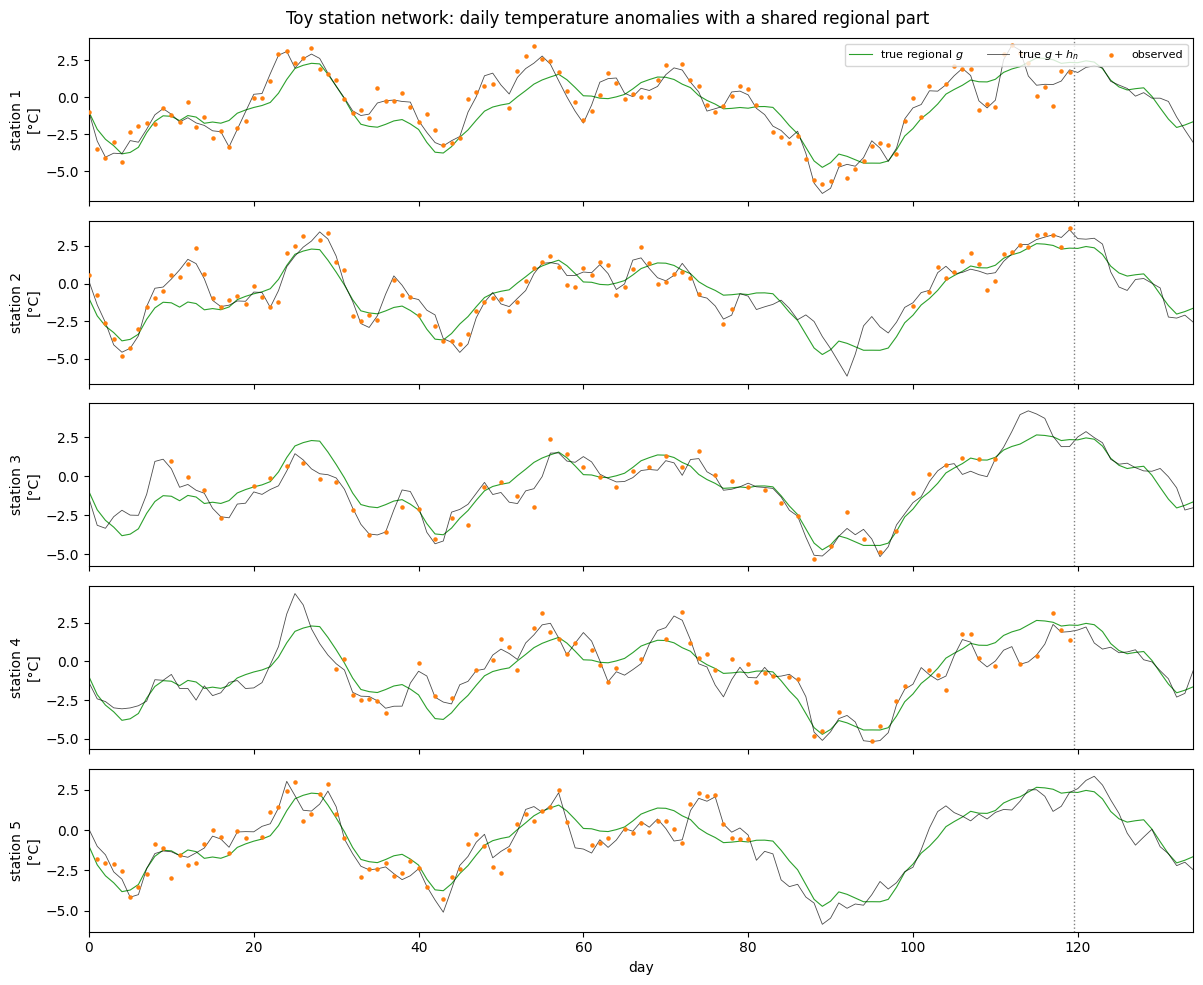

In [5]:
fig, axes = plt.subplots(n_stations, 1, figsize=(12, 10), sharex=True)
for n, ax in enumerate(axes):
    ax.plot(days, g_true, "C2-", lw=0.8, label="true regional $g$")
    ax.plot(days, signal_true[n], "k-", lw=0.6, alpha=0.7, label="true $g + h_n$")
    ax.scatter(
        times_per_station[n], y_per_station[n], c="C1", s=5, zorder=5, label="observed"
    )
    ax.axvline(LAST_REPORT - 0.5, color="grey", ls=":", lw=1)
    ax.set_ylabel(f"station {n + 1}\n[°C]")
axes[0].legend(loc="upper right", fontsize=8, ncol=3)
axes[-1].set_xlabel("day")
axes[-1].set_xlim(0, N_DAYS - 1)
fig.suptitle(
    "Toy station network: daily temperature anomalies with a shared regional part"
)
plt.tight_layout()
plt.show()

The green line is the same in every panel. The stations follow it closely and differ from it by their fast local wiggles, so on a day when station 2 is in its outage, the stations that still report say a lot about its anomaly. In Example 2's model they told it nothing about its path, only about its kernel.

## 2. The merged grid with `from_sites`

`SharedPlusSiteMarkovGP.from_sites` takes the regional kernel, the local kernel and one array of days and one array of values per station, as `pad_sites` did. It returns the model on the merged grid $\mathcal{T}_y$ and the $(T, N_\Omega)$ array $\mathbf{Y}$, which is `NaN` wherever a station did not report. The model keeps the merged days and the mask. Here we build it with the true kernels, and inside the NumPyro model we rebuild it on the same grid with the sampled ones. Every entry that a station did not report is masked, so it enters neither the value of the log marginal nor its gradient.

In [6]:
# Shapes: N_Ω = 5 stations; T merged days; D_x = D_g + N_Ω D_h

# today (pyrox_ssm)
# 𝒯_y = ⋃ₙ 𝒯_y,n, Y with NaN where o_n,k = 0, and the (T, N_Ω) mask
network_true, y_grid = SharedPlusSiteMarkovGP.from_sites(  # → model, (T, N_Ω)
    regional_sde_true, local_sde_true, times_per_station, y_per_station
)
grid_times = network_true.times  # → (T,)
grid_mask = network_true.mask  # → (T, N_Ω) bool
n_grid = grid_times.shape[0]
# |𝒪_k| = ∑ₙ o_n,k, the stations reporting on day t_k
reporting = einx.sum("k n -> k", grid_mask)  # (T, N_Ω) bool → (T,)
print(f"y_grid {y_grid.shape}, mask {grid_mask.shape} {grid_mask.dtype}")
print(
    f"T = {n_grid} merged days, from day {int(grid_times[0])} to {int(grid_times[-1])}"
)
print(f"observed (day, station) pairs: {int(grid_mask.sum())} = {sum(record_lengths)}")
print(f"NaN entries in y_grid: {int(jnp.isnan(y_grid).sum())}")
counts = np.bincount(np.asarray(reporting), minlength=n_stations + 1)
print(f"days with 1, …, {n_stations} stations reporting: {counts[1:].tolist()}")
print(
    f"state dimension D_x = {network_true.shared.state_dim} + {n_stations} x "
    f"{network_true.site.state_dim} = {network_true.state_dim}"
)

y_grid (120, 5), mask (120, 5) bool
T = 120 merged days, from day 0 to 119
observed (day, station) pairs: 391 = 391
NaN entries in y_grid: 209
days with 1, …, 5 stations reporting: [4, 24, 42, 37, 13]
state dimension D_x = 2 + 5 x 2 = 12


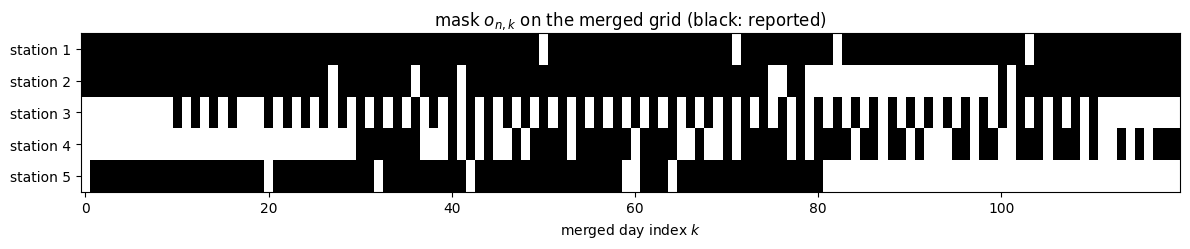

In [7]:
fig, ax = plt.subplots(figsize=(12, 2.6))
ax.imshow(
    np.asarray(grid_mask).T,
    aspect="auto",
    cmap="Greys",
    interpolation="nearest",
    extent=(-0.5, n_grid - 0.5, n_stations - 0.5, -0.5),
)
ax.set_yticks(range(n_stations), [f"station {n + 1}" for n in range(n_stations)])
ax.set_xlabel("merged day index $k$")
ax.set_title(r"mask $o_{n,k}$ on the merged grid (black: reported)")
plt.tight_layout()
plt.show()

Unlike Example 2's padded rows, every column of the mask is the same day at every station, which is what lets the regional block of the state link the stations day by day. A day with three stations reporting is one Kalman update with three rows of $\mathbf{H}$.

As a check of the exactness claim, we compare `log_marginal` at the true parameters with the dense Gaussian over all the observed (day, station) pairs, whose covariance is $k_g(t, t') + [n = n'] k_h(t, t') + [n = n', t = t'] \sigma_\varepsilon^2$ for the pairs $(t, n)$ and $(t', n')$. The dense one needs the closed-form Matérn-3/2 kernel and a Cholesky factor of a matrix with one row per observation.

In [8]:
def matern32(lag, variance, lengthscale):
    """Closed-form k_Matérn-3/2 at the lag t − t′."""
    # r = √3 |t − t′| / ℓ
    scaled = jnp.sqrt(3.0) * jnp.abs(lag) / lengthscale
    # k = σ² (1 + r) exp(−r)
    return variance * (1.0 + scaled) * jnp.exp(-scaled)


# Shapes: N_obs = ∑ₙ N_n observed pairs

obs_times = jnp.concatenate(times_per_station)  # → (N_obs,)
obs_station = jnp.concatenate(  # → (N_obs,)
    [jnp.full(record_lengths[n], n) for n in range(n_stations)]
)
obs_values = jnp.concatenate(y_per_station)  # → (N_obs,)
# t − t′ for every pair of observations
lags = einx.subtract("i, j -> i j", obs_times, obs_times)  # → (N_obs, N_obs)
# [n = n′]
same_station = einx.equal("i, j -> i j", obs_station, obs_station)
# k_g(t, t′)
gram_regional = matern32(  # → (N_obs, N_obs)
    lags, truth["regional_variance"], truth["regional_lengthscale"]
)
# [n = n′] k_h(t, t′)
gram_local = same_station * matern32(  # → (N_obs, N_obs)
    lags, truth["local_variance"], truth["local_lengthscale"]
)
noise_cov = truth["noise_var"] * jnp.eye(obs_times.shape[0])  # → (N_obs, N_obs)
# Σ_y = K_g + K_h + σ_ε² I
obs_cov = gram_regional + gram_local + noise_cov  # → (N_obs, N_obs)
# today (jax)
# log 𝒩(y; 0, Σ_y), the dense reference
dense_lml = multivariate_normal.logpdf(  # → ()
    obs_values, jnp.zeros(obs_times.shape[0]), obs_cov
)
# today (pyrox_ssm)
# log p(Y ∣ θ), one Kalman filter pass over the T merged days
kalman_lml = network_true.log_marginal(y_grid, truth["noise_var"])  # → ()
print(f"N_obs = {obs_times.shape[0]} observed pairs")
print(f"dense Gaussian : log p = {float(dense_lml):.10f}")
print(f"Kalman, merged : log p = {float(kalman_lml):.10f}")
print(f"relative difference: {float(jnp.abs(kalman_lml / dense_lml - 1.0)):.1e}")

N_obs = 391 observed pairs
dense Gaussian : log p = -552.8164935945
Kalman, merged : log p = -552.8164935945
relative difference: 2.2e-16


## 3. The model as a plain NumPyro function

We give the regional and the local kernel the same priors, Example 1's priors for $\sigma_f^2$ and $\ell$: $\sigma_g^2, \sigma_h^2 \sim \mathrm{LogNormal}(\log 2, 1)$ and $\ell_g, \ell_h \sim \mathrm{LogNormal}(\log 7, 1)$. So nothing in the priors says which part is slow or large, and only the data separate the regional signal from the local ones. The noise variance keeps Example 1's prior too, $\sigma_\varepsilon^2 \sim \mathrm{LogNormal}(\log 0.1, 1)$. The model rebuilds `SharedPlusSiteMarkovGP` on the merged days and mask of `network_true` with the sampled kernels, and `numpyro.factor` adds its `log_marginal` as one site named `"y"`. The local kernel has scalar hyperparameters, which `SharedPlusSiteMarkovGP` pools over the stations. A local kernel whose leaves have a leading axis of length $N_\Omega$ would give each station its own, which is how Example 2's hierarchy would go on top of this model.

In [9]:
def network_model(times, mask, y_grid):
    # Shapes: T merged days; N_Ω = 5 stations; D_θ = 5 parameters

    # today (numpyro): the five sample sites of θ
    # σ_g² ~ LogNormal(log 2, 1)
    regional_variance = numpyro.sample(
        "regional_variance", dist.LogNormal(jnp.log(2.0), 1.0)
    )
    # ℓ_g ~ LogNormal(log 7, 1)
    regional_lengthscale = numpyro.sample(
        "regional_lengthscale", dist.LogNormal(jnp.log(7.0), 1.0)
    )
    # σ_h² ~ LogNormal(log 2, 1)
    local_variance = numpyro.sample("local_variance", dist.LogNormal(jnp.log(2.0), 1.0))
    # ℓ_h ~ LogNormal(log 7, 1)
    local_lengthscale = numpyro.sample(
        "local_lengthscale", dist.LogNormal(jnp.log(7.0), 1.0)
    )
    # σ_ε² ~ LogNormal(log 0.1, 1)
    noise_var = numpyro.sample("noise_var", dist.LogNormal(jnp.log(0.1), 1.0))

    # today (pyrox_ssm)
    # k_Matérn-3/2(t, t'; σ_g², ℓ_g) as a linear SDE
    regional_sde = MaternSDE(regional_variance, regional_lengthscale, order=1)
    # today (pyrox_ssm)
    # k_Matérn-3/2(t, t'; σ_h², ℓ_h), pooled over the stations
    local_sde = MaternSDE(local_variance, local_lengthscale, order=1)
    # today (pyrox_ssm)
    # x_k = (x_g,k, x_h,1,k, …, x_h,N_Ω,k) on the merged grid
    network = SharedPlusSiteMarkovGP(regional_sde, local_sde, times, mask)
    # today (pyrox_ssm)
    # log p(Y ∣ θ) = ∑ₖ log 𝒩(y_𝒪ₖ; H_𝒪ₖ μ_x,k∣k−1, H_𝒪ₖ Σ_x,k∣k−1 H_𝒪ₖᵀ + σ_ε² I)
    log_marginal = network.log_marginal(y_grid, noise_var)  # (T, N_Ω) → ()
    # today (numpyro)
    numpyro.factor("y", log_marginal)


# today (numpyro)
seeded_model = handlers.seed(network_model, rng_seed=0)
# today (numpyro)
trace = handlers.trace(seeded_model).get_trace(grid_times, grid_mask, y_grid)
for name, site in trace.items():
    kind = "factor" if isinstance(site["fn"], dist.Unit) else type(site["fn"]).__name__
    print(f"site {name!r:24} {kind:<10} value shape={tuple(jnp.shape(site['value']))}")

site 'regional_variance'      LogNormal  value shape=()
site 'regional_lengthscale'   LogNormal  value shape=()
site 'local_variance'         LogNormal  value shape=()
site 'local_lengthscale'      LogNormal  value shape=()
site 'noise_var'              LogNormal  value shape=()
site 'y'                      factor     value shape=(0,)


So the trace holds five scalar sample sites and one factor. The regional path and the five local paths, $D_x = 12$ numbers on each of the $T$ days, are integrated out by the one Kalman filter, so NUTS sees five unconstrained values whatever the number of days.

## 4. NUTS

We run two chains of 200 draws after 200 warm-up steps with a dense mass matrix, started at the prior medians (`init_to_median`), and run the chains in parallel on two CPU devices as in Example 2. The wall-clock time includes JIT compilation.

In [10]:
# Shapes: D_θ = 5 parameters; 2 chains × 200 = 400 posterior draws

# today (numpyro)
nuts_kernel = NUTS(network_model, dense_mass=True, init_strategy=init_to_median)
# today (numpyro)
nuts = MCMC(
    nuts_kernel,
    num_warmup=200,
    num_samples=200,
    num_chains=2,
    chain_method="parallel",
    progress_bar=False,
)
t0 = time.perf_counter()
# today (numpyro)
# 400 draws θ ~ p(θ ∣ Y)
nuts.run(jr.PRNGKey(1), grid_times, grid_mask, y_grid, extra_fields=("num_steps",))
jax.block_until_ready(nuts.get_samples())
nuts_seconds = time.perf_counter() - t0
nuts.print_summary()
nuts_samples = nuts.get_samples()  # → {name: (400,)}
extra_fields = nuts.get_extra_fields()
n_div = int(extra_fields["diverging"].sum())  # → ()
n_grad = int(extra_fields["num_steps"].sum())  # → ()
print(
    f"NUTS wall-clock: {nuts_seconds:.1f} s for 2 chains x 400 iterations, "
    f"{n_div} divergences"
)
print(
    f"leapfrog steps after warm-up: {n_grad}, {n_grad / 400:.1f} per draw "
    f"(one Kalman filter pass over a {network_true.state_dim}-dimensional state "
    "and its gradient each)"
)


                            mean       std    median      5.0%     95.0%     n_eff     r_hat
     local_lengthscale      1.69      0.24      1.68      1.30      2.05    239.58      1.02
        local_variance      1.12      0.16      1.09      0.84      1.34    232.43      1.01
             noise_var      0.14      0.06      0.14      0.04      0.23    226.84      1.01
  regional_lengthscale      6.92      1.46      6.70      4.57      9.06    434.12      1.00
     regional_variance      3.81      1.38      3.51      1.84      5.91    258.26      1.00

Number of divergences: 0


NUTS wall-clock: 57.1 s for 2 chains x 400 iterations, 0 divergences
leapfrog steps after warm-up: 4076, 10.2 per draw (one Kalman filter pass over a 12-dimensional state and its gradient each)


The chains mixed well: we get no divergences, every $\hat{R}$ is between 1.00 and 1.02, and the smallest effective sample size is 227 (the noise variance). NUTS took 10.2 leapfrog steps per draw after warm-up, and the whole run took 57.1 s.

## 5. The hyperparameters against the truth

For each parameter we print the posterior mean, standard deviation and 90 % interval, next to the value we simulated the data with.

In [11]:
def summarise(draws, truth_value):
    """Posterior mean, sd, 90 % interval and whether it holds the truth."""
    values = np.asarray(draws)
    lo, hi = np.percentile(values, [5, 95])
    inside = "in" if lo <= truth_value <= hi else "out"
    return (
        f"{truth_value:>8.2f}  {values.mean():>8.3f} ± {values.std():<6.3f}  "
        f"[{lo:>7.3f}, {hi:>7.3f}] {inside:>3}"
    )


param_names = list(truth)
TABLE_HEADER = f"{'parameter':<24}{'truth':>8}  {'mean ± sd':>17}  {'90% interval':>19}"
print(TABLE_HEADER)
for name in param_names:
    print(f"{name:<24}{summarise(nuts_samples[name], truth[name])}")

parameter                  truth          mean ± sd         90% interval
regional_variance           4.00     3.809 ± 1.375   [  2.096,   6.588]  in
regional_lengthscale        8.00     6.917 ± 1.461   [  4.943,   9.473]  in
local_variance              1.00     1.115 ± 0.165   [  0.881,   1.383]  in
local_lengthscale           2.00     1.694 ± 0.238   [  1.306,   2.077]  in
noise_var                   0.25     0.139 ± 0.057   [  0.044,   0.233] out


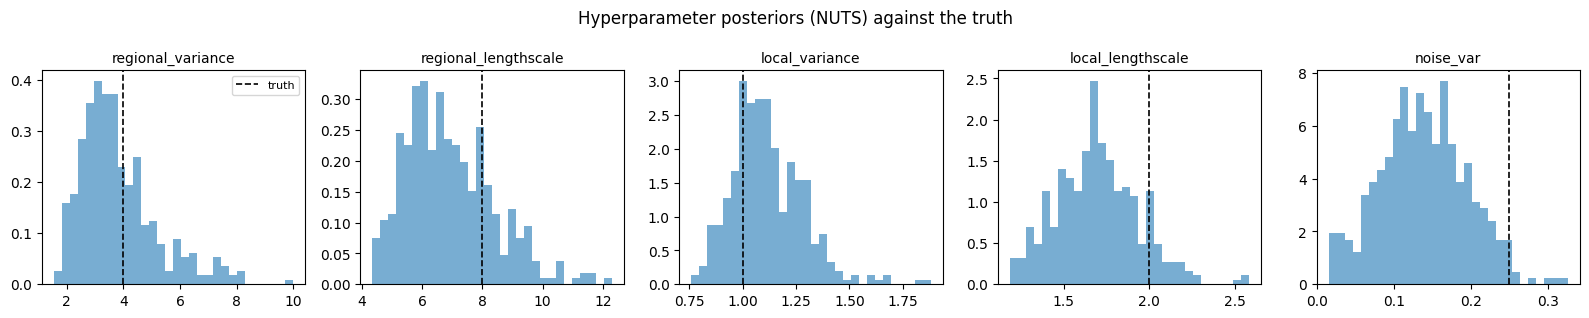

In [12]:
fig, axes = plt.subplots(1, 5, figsize=(16, 3.2))
for ax, name in zip(axes, param_names, strict=True):
    ax.hist(
        np.asarray(nuts_samples[name]), bins=30, density=True, color="C0", alpha=0.6
    )
    ax.axvline(truth[name], color="k", ls="--", lw=1.2, label="truth")
    ax.set_title(name, fontsize=10)
axes[0].legend(fontsize=8)
fig.suptitle("Hyperparameter posteriors (NUTS) against the truth")
plt.tight_layout()
plt.show()

Four of the five 90 % intervals contain the true value. The local kernel is the best determined, with $\sigma_h^2$ at 1.12 ± 0.17 (true 1) and $\ell_h$ at 1.69 ± 0.24 days (true 2), because every station contributes its own local path to it. The regional kernel is much less certain, $\sigma_g^2$ at 3.81 ± 1.38 (true 4) and $\ell_g$ at 6.92 ± 1.46 days (true 8). There is only one regional path, and 120 days of it span only 15 of its lengthscales. The miss is the noise variance, at 0.14 ± 0.06 against 0.25, with an interval that stops at 0.233. The local anomaly and the noise are both fast and both private to a station, so the posterior trades a little of the noise for a slightly shorter and larger local anomaly, as we see in the two local rows.

## 6. Decomposition and prediction at every station

A posterior draw $e \in \mathcal{E}$ gives $\boldsymbol{\theta}^{(e)}$. For one draw we build the model on an extended grid, the merged days together with the test times $t_*$, every 12 hours from day 0 to day 134.5. A test time that is not a station day is a row of the mask with no station reporting, so the filter only predicts there. `decompose` runs the Kalman filter and RTS smoother on that model and returns the smoothed means of the regional part, $\mathbb{E}[g(t_*) \mid \mathbf{Y}; \boldsymbol{\theta}^{(e)}]$, and of every local part, $\mathbb{E}[h_n(t_*) \mid \mathbf{Y}; \boldsymbol{\theta}^{(e)}]$. `decompose` returns no variances, so we take them from the smoothed state covariances $\boldsymbol{\Sigma}_{x,* \mid T} \in \mathbb{R}^{D_x \times D_x}$ of `as_lgssm(noise_var).smooth(...)`, which its docstring points to. With $\mathbf{h}_n \in \mathbb{R}^{D_x}$ row $n$ of $\mathbf{H}$, and $\mathbf{h}_g, \mathbf{h}_{h,n} \in \mathbb{R}^{D_x}$ the same row with only its regional or only its local block kept, so that $\mathbf{h}_n = \mathbf{h}_g + \mathbf{h}_{h,n}$,

$$\mathbb{V}[g(t_*) \mid \mathbf{Y}; \boldsymbol{\theta}^{(e)}] = \mathbf{h}_g^\top \boldsymbol{\Sigma}_{x,* \mid T} \mathbf{h}_g$$

$$\mathbb{V}[h_n(t_*) \mid \mathbf{Y}; \boldsymbol{\theta}^{(e)}] = \mathbf{h}_{h,n}^\top \boldsymbol{\Sigma}_{x,* \mid T} \mathbf{h}_{h,n}$$

$$\mathbb{V}[g(t_*) + h_n(t_*) \mid \mathbf{Y}; \boldsymbol{\theta}^{(e)}] = \mathbf{h}_n^\top \boldsymbol{\Sigma}_{x,* \mid T} \mathbf{h}_n$$

The last one is not the sum of the first two, because given the data the regional and the local part of a station are correlated: a warm reading can be either. A new observation $y_{n,*}$ adds $(\sigma_\varepsilon^{(e)})^2$. We do this for $N_{\mathcal{E}} = 100$ NUTS draws with `jax.vmap` and average each mean and variance over the draws as in Example 1, so every band carries the hyperparameter uncertainty as well as the uncertainty of the paths.

In [13]:
# Shapes: N_Ω = 5 stations; M = 270 test times (every 12 h); D_x = 12; N_E = 100 draws

N_DRAWS = 100
t_dense = jnp.arange(0.0, N_DAYS, 0.5)  # → (M,)
# day d sits at index 2d of the 12-hour grid
grid_index = (2 * grid_times).astype(int)  # → (T,)
# o_n,* = o_n,k on a merged day, 0 at every other test time
dense_mask = jnp.zeros((t_dense.shape[0], n_stations), dtype=bool)  # → (M, N_Ω)
dense_mask = dense_mask.at[grid_index].set(grid_mask)
# Y on the test grid, NaN where nothing was reported
y_dense = jnp.full((t_dense.shape[0], n_stations), jnp.nan)  # → (M, N_Ω)
y_dense = y_dense.at[grid_index].set(y_grid)


def decompose_one(theta):
    # Shapes: M test times; N_Ω stations; D_x = D_g + N_Ω D_h
    # today (pyrox_ssm)
    regional_sde = MaternSDE(
        theta["regional_variance"], theta["regional_lengthscale"], order=1
    )
    # today (pyrox_ssm)
    local_sde = MaternSDE(theta["local_variance"], theta["local_lengthscale"], order=1)
    # today (pyrox_ssm)
    # the model on 𝒯_y ∪ 𝒯_*, test times masked out of the update
    network = SharedPlusSiteMarkovGP(regional_sde, local_sde, t_dense, dense_mask)
    # today (pyrox_ssm)
    # 𝔼[g(t_*) ∣ Y; θ⁽ᵉ⁾], 𝔼[h_n(t_*) ∣ Y; θ⁽ᵉ⁾]
    g_mean, h_mean = network.decompose(y_dense, theta["noise_var"])  # → (M,), (M, N_Ω)
    # today (pyrox_ssm)
    lgssm = network.as_lgssm(theta["noise_var"])
    # today (pyrox_ssm)
    # Σ_x,*∣T, the smoothed covariance of the joint state
    _, state_cov, _ = lgssm.smooth(y_dense, mask=network.mask)  # → (M, D_x, D_x)
    obs_rows = lgssm.obs_model  # → (N_Ω, D_x)
    # 1 on the regional block of the state, 0 on the local blocks
    in_regional = jnp.arange(network.state_dim) < network.shared.state_dim
    # h_g, the regional block of any row of H
    regional_row = obs_rows[0] * in_regional  # → (D_x,)
    # h_h,n = h_n − h_g, station n's local block
    local_rows = obs_rows - regional_row  # → (N_Ω, D_x)
    # h_gᵀ Σ_x,*∣T h_g
    g_var = einx.dot(  # → (M,)
        "m d e, d, e -> m", state_cov, regional_row, regional_row
    )
    # h_h,nᵀ Σ_x,*∣T h_h,n
    h_var = einx.dot(  # → (M, N_Ω)
        "m d e, n d, n e -> m n", state_cov, local_rows, local_rows
    )
    # h_nᵀ Σ_x,*∣T h_n, the variance of g + h_n
    total_var = einx.dot(  # → (M, N_Ω)
        "m d e, n d, n e -> m n", state_cov, obs_rows, obs_rows
    )
    # 𝔼[g + h_n ∣ Y; θ⁽ᵉ⁾]
    total_mean = einx.add("m, m n -> m n", g_mean, h_mean)  # → (M, N_Ω)
    return {
        "g_mean": g_mean,
        "g_var": g_var,
        "h_mean": h_mean,
        "h_var": h_var,
        "total_mean": total_mean,
        "total_var": total_var,
        "noise_var": theta["noise_var"],
    }


def mixture(means, variances):
    """Mean and variance of the equal-weight mixture over the draw axis."""
    # μ̄_* = (1/N_E) ∑ₑ μ_*⁽ᵉ⁾
    mean = einx.mean("member ... -> ...", means)
    # (1/N_E) ∑ₑ (μ_*⁽ᵉ⁾ − μ̄_*)²
    spread = einx.var("member ... -> ...", means)
    # (1/N_E) ∑ₑ (σ_*⁽ᵉ⁾)²
    variance_mean = einx.mean("member ... -> ...", variances)
    # 𝕍 ≈ (1/N_E) ∑ₑ (σ_*⁽ᵉ⁾)² + spread
    return mean, variance_mean + spread


def draws_from(samples):
    """N_E draws evenly spaced through the chains."""
    num_samples = samples["noise_var"].shape[0]
    idx = jnp.linspace(0, num_samples - 1, N_DRAWS).astype(int)  # → (N_E,)
    return {name: values[idx] for name, values in samples.items()}


t0 = time.perf_counter()
# today (jax)
decompose_draws = jax.jit(jax.vmap(decompose_one))
per_draw = decompose_draws(draws_from(nuts_samples))  # → {name: (N_E, M, …)}
jax.block_until_ready(per_draw)
pred_seconds = time.perf_counter() - t0

g_mean, g_var = mixture(per_draw["g_mean"], per_draw["g_var"])  # → 2 × (M,)
h_mean, h_var = mixture(per_draw["h_mean"], per_draw["h_var"])  # → 2 × (M, N_Ω)
total_mean, total_var = mixture(  # → 2 × (M, N_Ω)
    per_draw["total_mean"], per_draw["total_var"]
)
# (σ_n,*⁽ᵉ⁾)² + (σ_ε⁽ᵉ⁾)² for a new observation y_n,*
new_obs_var = einx.add(  # → (N_E, M, N_Ω)
    "member m n, member -> member m n", per_draw["total_var"], per_draw["noise_var"]
)
_, y_var = mixture(per_draw["total_mean"], new_obs_var)  # → (M, N_Ω)
# the decomposition adds up to the smoothed station mean
summed = einx.add("m, m n -> m n", g_mean, h_mean)  # → (M, N_Ω)
max_gap = float(jnp.max(jnp.abs(summed - total_mean)))  # → ()
print(
    f"decomposition at {t_dense.shape[0]} times x {n_stations} stations for "
    f"{N_DRAWS} draws: {pred_seconds:.1f} s (with JIT)"
)
print(f"max |E[g] + E[h_n] - E[g + h_n]| = {max_gap:.1e}")

decomposition at 270 times x 5 stations for 100 draws: 4.0 s (with JIT)
max |E[g] + E[h_n] - E[g + h_n]| = 1.8e-15


Each row of the figure below is one station. On the left, the dark band is $\pm 2\sigma$ for the latent $g + h_n$ and the light band $\pm 2\sigma$ for a new observation. The thin black line is the true $g + h_n$, the dots are the days the station reported and the red crosses the days it missed (including the forecast after the dotted line), which the model never saw. On the right is the decomposition of the same station: the regional part in green and the local part in purple, each with its $\pm 2\sigma$ band and its truth as a thin line of the same colour.

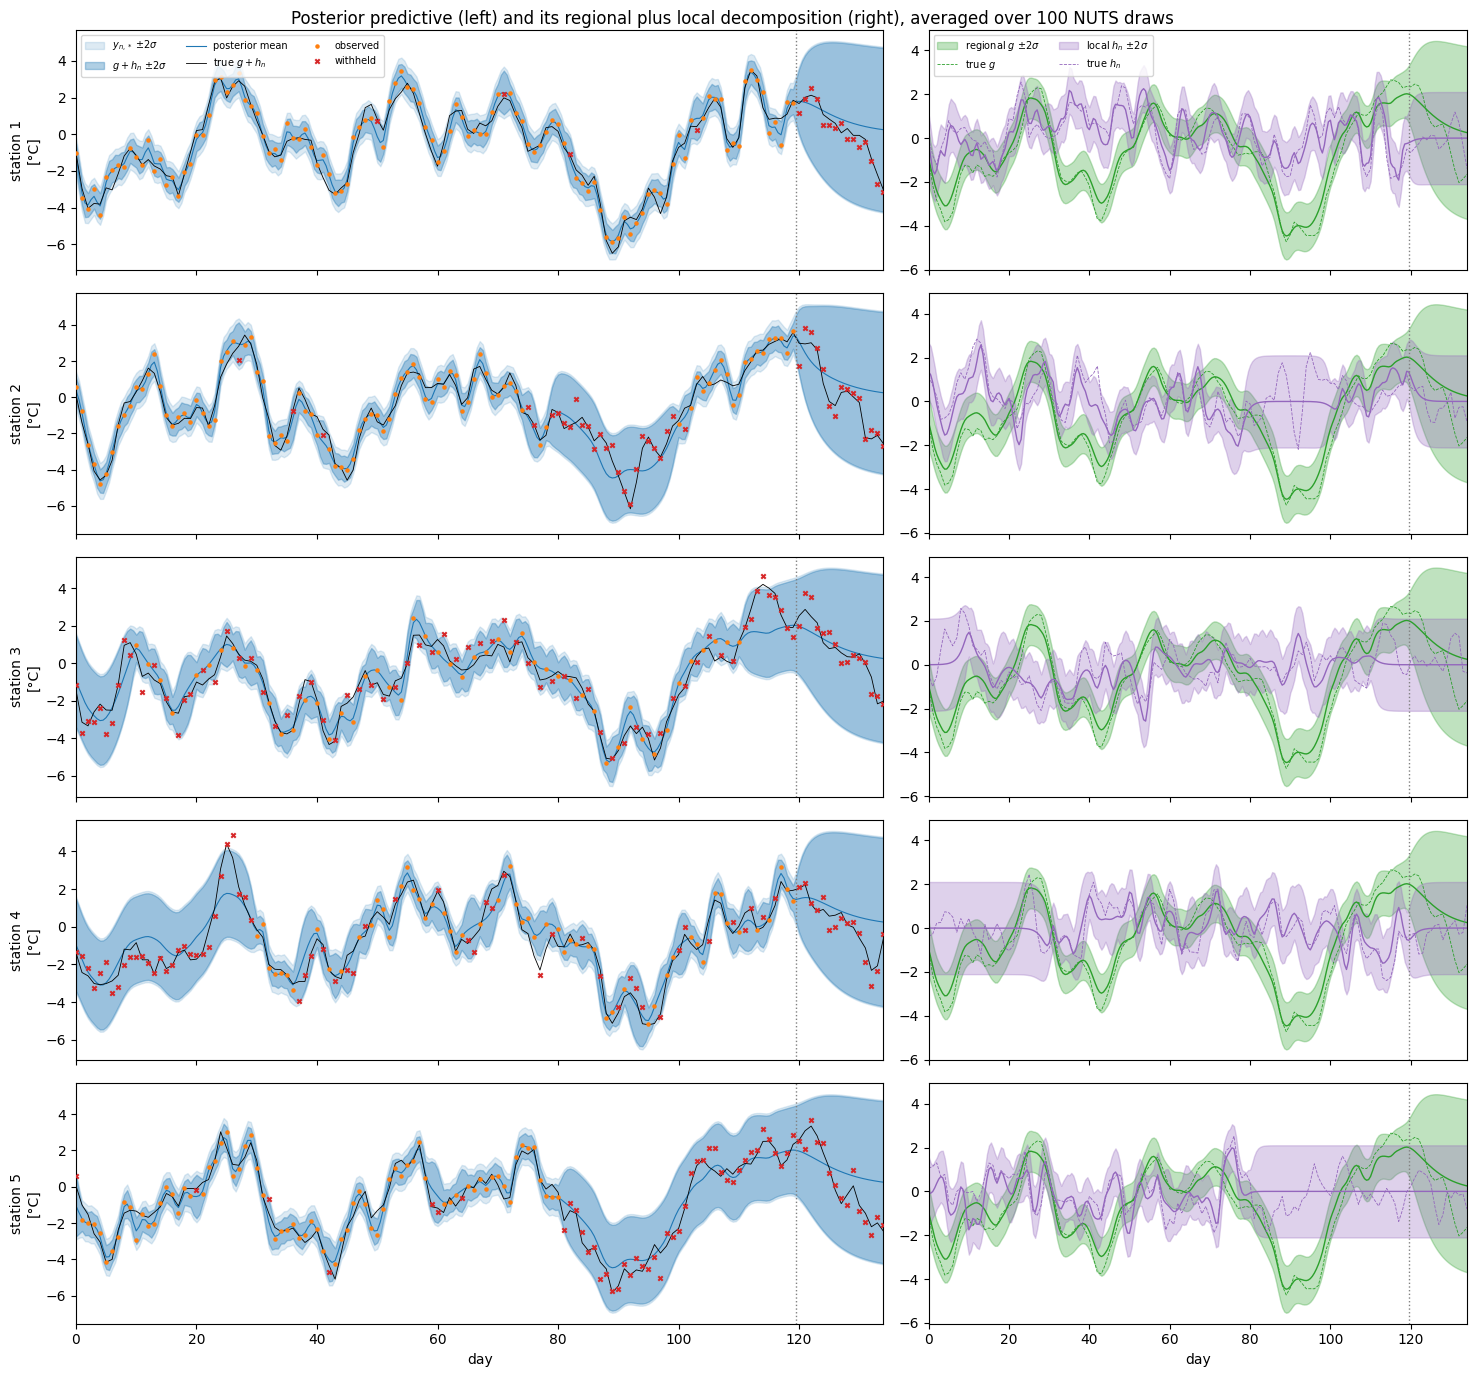

In [14]:
t_grid = np.asarray(t_dense)  # → (M,)
y_sd = np.sqrt(np.asarray(y_var))  # → (M, N_Ω)
total_sd = np.sqrt(np.asarray(total_var))  # → (M, N_Ω)
g_sd = np.sqrt(np.asarray(g_var))  # → (M,)
h_sd = np.sqrt(np.asarray(h_var))  # → (M, N_Ω)
withheld_true = ~np.asarray(reported_true)  # → (N_Ω, N_days) bool

fig, axes = plt.subplots(
    n_stations, 2, figsize=(15, 14), sharex=True, gridspec_kw={"width_ratios": [3, 2]}
)
for n in range(n_stations):
    ax = axes[n, 0]
    ax.fill_between(
        t_grid,
        total_mean[:, n] - 2 * y_sd[:, n],
        total_mean[:, n] + 2 * y_sd[:, n],
        color="C0",
        alpha=0.15,
        label=r"$y_{n,*}$ $\pm 2\sigma$",
    )
    ax.fill_between(
        t_grid,
        total_mean[:, n] - 2 * total_sd[:, n],
        total_mean[:, n] + 2 * total_sd[:, n],
        color="C0",
        alpha=0.35,
        label=r"$g + h_n$ $\pm 2\sigma$",
    )
    ax.plot(t_grid, total_mean[:, n], "C0", lw=0.8, label="posterior mean")
    ax.plot(days, signal_true[n], "k-", lw=0.6, label="true $g + h_n$")
    ax.scatter(
        times_per_station[n], y_per_station[n], c="C1", s=5, zorder=5, label="observed"
    )
    ax.scatter(
        days[withheld_true[n]],
        y_true[n][withheld_true[n]],
        marker="x",
        c="C3",
        s=10,
        zorder=5,
        label="withheld",
    )
    ax.axvline(LAST_REPORT - 0.5, color="grey", ls=":", lw=1)
    ax.set_ylabel(f"station {n + 1}\n[°C]")

    ax = axes[n, 1]
    ax.fill_between(
        t_grid,
        g_mean - 2 * g_sd,
        g_mean + 2 * g_sd,
        color="C2",
        alpha=0.3,
        label=r"regional $g$ $\pm 2\sigma$",
    )
    ax.plot(t_grid, g_mean, "C2", lw=1.0)
    ax.plot(days, g_true, "C2", lw=0.6, ls="--", label="true $g$")
    ax.fill_between(
        t_grid,
        h_mean[:, n] - 2 * h_sd[:, n],
        h_mean[:, n] + 2 * h_sd[:, n],
        color="C4",
        alpha=0.3,
        label=r"local $h_n$ $\pm 2\sigma$",
    )
    ax.plot(t_grid, h_mean[:, n], "C4", lw=1.0)
    ax.plot(days, h_true[n], "C4", lw=0.6, ls="--", label="true $h_n$")
    ax.axvline(LAST_REPORT - 0.5, color="grey", ls=":", lw=1)
axes[0, 0].legend(loc="upper left", fontsize=7, ncol=3)
axes[0, 1].legend(loc="upper left", fontsize=7, ncol=2)
axes[-1, 0].set_xlabel("day")
axes[-1, 1].set_xlabel("day")
axes[-1, 0].set_xlim(0, N_DAYS - 1)
fig.suptitle(
    "Posterior predictive (left) and its regional plus local decomposition (right), "
    "averaged over 100 NUTS draws"
)
plt.tight_layout()
plt.show()

Inside each record the band is narrow and follows the observations. The interesting part is where a station has no data. During station 2's outage (days 80 to 99) the posterior mean follows the cold spell that stations 1, 3 and 4 saw, and the right-hand panel shows why: the regional part stays as narrow as elsewhere, while the station's local part falls back to zero with its prior band of $\pm 2 \sigma_h$. The same happens before station 4 starts and after station 5 stops. Station 3 is read every second day, and between two readings its band barely widens. In the forecast after day 119 the regional and the local parts both relax to zero.

The regional signal on its own, with every station's anomalies behind it, is the same green band as in the right-hand panels. No station measures $g$ directly, and yet the posterior mean follows the true path through every regional swing of the reporting days, including the cold spell around day 90, because the local parts of different stations average out. In the forecast it relaxes towards zero and its band widens to the prior spread.

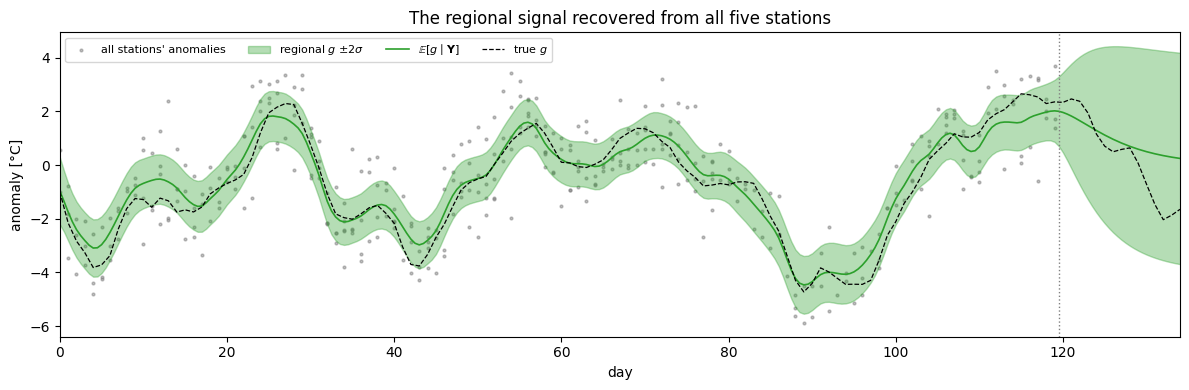

In [15]:
fig, ax = plt.subplots(figsize=(12, 4))
for n in range(n_stations):
    ax.scatter(
        times_per_station[n],
        y_per_station[n],
        c="grey",
        s=4,
        alpha=0.5,
        label="all stations' anomalies" if n == 0 else None,
    )
ax.fill_between(
    t_grid,
    g_mean - 2 * g_sd,
    g_mean + 2 * g_sd,
    color="C2",
    alpha=0.35,
    label=r"regional $g$ $\pm 2\sigma$",
)
ax.plot(t_grid, g_mean, "C2", lw=1.2, label=r"$\mathbb{E}[g \mid \mathbf{Y}]$")
ax.plot(days, g_true, "k--", lw=0.9, label="true $g$")
ax.axvline(LAST_REPORT - 0.5, color="grey", ls=":", lw=1)
ax.set_xlim(0, N_DAYS - 1)
ax.set_xlabel("day")
ax.set_ylabel("anomaly [°C]")
ax.set_title("The regional signal recovered from all five stations")
ax.legend(loc="upper left", fontsize=8, ncol=4)
plt.tight_layout()
plt.show()

Because the data are simulated, we know the regional and the local paths on every day and the value each station would have reported on every day it missed. Below we score the decomposition, with the RMSE of each posterior mean against its true path and the fraction of days on which the truth falls inside the $\pm 2\sigma$ band, over the 120 reporting days and over the 15-day forecast. The local part of a station is scored over the days from its first to its last report.

In [16]:
# Shapes: N_days = 135 simulated days; M = 270 test times; N_Ω = 5 stations

# day d sits at index 2d of the 12-hour grid
day_index = (2 * np.arange(N_DAYS)).astype(int)  # → (N_days,)
reporting_window = np.arange(N_DAYS) < LAST_REPORT  # → (N_days,) bool


def score(mean, sd, target, sel):
    """RMSE of the mean and the fraction of the target inside ±2σ, on sel."""
    # r = target − mean
    residual = np.asarray(target)[sel] - np.asarray(mean)[sel]
    # RMSE = √(mean of r²)
    rmse = float(np.sqrt(np.mean(residual**2)))
    # fraction of days with |r| < 2σ
    cover = float(np.mean(np.abs(residual) < 2.0 * np.asarray(sd)[sel]))
    return rmse, cover


print(f"{'component':<26}{'days':>6}{'RMSE':>10}{'coverage of ±2σ':>18}")
for label, sel in (
    ("regional g, days 0-119", reporting_window),
    ("regional g, forecast", ~reporting_window),
):
    rmse, cover = score(g_mean[day_index], g_sd[day_index], g_true, sel)
    print(f"{label:<26}{int(sel.sum()):>6}{rmse:>7.2f} °C{100 * cover:>15.1f} %")
for n in range(n_stations):
    first, last = int(times_per_station[n][0]), int(times_per_station[n][-1])
    span = (np.arange(N_DAYS) >= first) & (np.arange(N_DAYS) <= last)
    rmse, cover = score(h_mean[day_index, n], h_sd[day_index, n], h_true[n], span)
    label = f"local h_{n + 1}, days {first}-{last}"
    print(f"{label:<26}{int(span.sum()):>6}{rmse:>7.2f} °C{100 * cover:>15.1f} %")

component                   days      RMSE   coverage of ±2σ


regional g, days 0-119       120   0.47 °C           97.5 %
regional g, forecast          15   1.18 °C          100.0 %


local h_1, days 0-119        120   0.52 °C           98.3 %
local h_2, days 0-119        120   0.74 °C           94.2 %
local h_3, days 10-110       101   0.58 °C           95.0 %
local h_4, days 30-119        90   0.58 °C           97.8 %
local h_5, days 1-80          80   0.60 °C           93.8 %


Over the reporting days the posterior mean of the regional signal is 0.47 °C RMSE from the truth, and the truth is inside its $\pm 2\sigma$ band on 97.5 % of the days. The local parts are harder to recover, with RMSEs of 0.52 to 0.74 °C and coverage between 93.8 and 98.3 %, because each of them is a 1 °C signal that decorrelates over two days and that only one station sees. The largest local error is at station 2, whose local part is unconstrained during its 20-day outage. In the forecast the regional RMSE grows to 1.18 °C, and its band contains the truth on all 15 days.

For the predictions we score every day a station did not report, against the value it would have reported, $y_{n,*} = g + h_n + \varepsilon_n$. We split these days into four kinds: station 2's outage, the isolated gaps inside a record (random dropouts and station 3's days between readings), the reporting days outside a station's own record (before station 3 or 4 started, after station 3 or 5 stopped), when the other stations were still reporting, and the 15-day forecast after day 119.

In [17]:
# Shapes: N_Ω = 5 stations; N_days = 135 simulated days

first_day = np.array([int(t_n[0]) for t_n in times_per_station])  # → (N_Ω,)
last_day = np.array([int(t_n[-1]) for t_n in times_per_station])  # → (N_Ω,)
day_of = np.arange(N_DAYS)  # → (N_days,)
# t ≥ first day of station n
after_first = einx.greater_equal("d, n -> n d", day_of, first_day)
# t ≤ last day of station n
before_last = einx.less_equal("d, n -> n d", day_of, last_day)
# t inside [first, last] of station n's own record
in_record = after_first & before_last  # → (N_Ω, N_days) bool
in_outage = np.zeros((n_stations, N_DAYS), dtype=bool)  # → (N_Ω, N_days) bool
in_outage[1, 80:100] = True
withheld_kinds = {
    "outage (station 2)": withheld_true & in_outage,
    "gaps inside a record": withheld_true & in_record & ~in_outage,
    "outside its own record": withheld_true & ~in_record & reporting_window,
    "forecast (days 120-134)": withheld_true & ~reporting_window,
}


def score_withheld(mean, sd):
    """RMSE and ±2σ coverage of y_n,* on each kind of withheld day."""
    # (M, N_Ω) on the 12-hour grid → (N_Ω, N_days) on the days
    mean_days = einx.id("d n -> n d", np.asarray(mean)[day_index])
    sd_days = einx.id("d n -> n d", np.asarray(sd)[day_index])
    rows = {}
    for label, sel in withheld_kinds.items():
        rows[label] = (int(sel.sum()), *score(mean_days, sd_days, y_true, sel))
    return rows


joint_scores = score_withheld(total_mean, y_sd)
print(f"{'withheld days':<26}{'days':>6}{'RMSE':>10}{'coverage of ±2σ':>18}")
for label, (count, rmse, cover) in joint_scores.items():
    print(f"{label:<26}{count:>6}{rmse:>7.2f} °C{100 * cover:>15.1f} %")

withheld days               days      RMSE   coverage of ±2σ
outage (station 2)            20   1.11 °C          100.0 %
gaps inside a record         100   0.77 °C           98.0 %
outside its own record        89   1.08 °C           96.6 %
forecast (days 120-134)       75   1.48 °C          100.0 %


Every kind of withheld day has at least 96.6 % of its values inside the $\pm 2\sigma$ band for a new observation, slightly more than the nominal 95 %. The isolated gaps are the easiest (RMSE 0.77 °C), as in Examples 1 and 2. Inside station 2's outage and outside a station's own record the RMSE is 1.11 and 1.08 °C, close to $\sqrt{\sigma_h^2 + \sigma_\varepsilon^2} = 1.12$ °C at the true values. This is the error we expect when the regional part is known from the other stations and only the station's own local part and its noise are not. The forecast, where nobody reports, has the largest error (1.48 °C).

## 7. What the regional signal buys

To see what the joint model buys, we fit the network with Example 2's structure instead, in which each station has one anomaly $f_n \sim \mathcal{GP}(0, k_\text{Matérn-3/2}(t, t'; \sigma_f^2, \ell))$ of its own and the anomalies of different stations are independent. We pool $\sigma_f^2$, $\ell$ and $\sigma_\varepsilon^2$ over the stations (Example 1's priors), so this model has three parameters and shares only them. As in Example 2, `pad_sites` pads the records, and one vmapped `MarkovGPPrior.log_marginal` per station goes into one factor. Both models see the same data, and we score their predictions on the same withheld days.

In [18]:
def station_log_marginal(t_n, y_n, o_n, variance, lengthscale, noise_var):
    # Shapes: N padded steps; D_h = 2
    # today (pyrox_ssm)
    # k_Matérn-3/2(t, t'; σ_f², ℓ) as a linear SDE
    sde = MaternSDE(variance, lengthscale, order=1)
    # today (pyrox_ssm)
    prior = MarkovGPPrior(sde, t_n)
    # today (pyrox_ssm)
    # log p(y_n ∣ σ_f², ℓ, σ_ε²) by station n's own Kalman filter
    return prior.log_marginal(y_n, noise_var, mask=o_n)  # (N,) → ()


def independent_model(times, y, mask):
    # Shapes: N_Ω = 5 stations; N padded steps; D_θ = 3 parameters

    # today (numpyro): Example 1's priors, pooled over the stations
    # σ_f² ~ LogNormal(log 2, 1)
    variance = numpyro.sample("variance", dist.LogNormal(jnp.log(2.0), 1.0))
    # ℓ ~ LogNormal(log 7, 1)
    lengthscale = numpyro.sample("lengthscale", dist.LogNormal(jnp.log(7.0), 1.0))
    # σ_ε² ~ LogNormal(log 0.1, 1)
    noise_var = numpyro.sample("noise_var", dist.LogNormal(jnp.log(0.1), 1.0))
    # today (jax)
    per_station = jax.vmap(station_log_marginal, in_axes=(0, 0, 0, None, None, None))
    # log p(y_n ∣ ·) for n = 1, …, N_Ω
    log_marginals = per_station(  # (N_Ω, N) → (N_Ω,)
        times, y, mask, variance, lengthscale, noise_var
    )
    # log p(Y ∣ ·) = ∑ₙ log p(y_n ∣ ·)
    log_likelihood = einx.sum("n ->", log_marginals)  # (N_Ω,) → ()
    # today (numpyro)
    numpyro.factor("y", log_likelihood)


# today (pyrox_ssm)
# T, Y, O padded per station, as in Example 2
padded_times, padded_y, padded_mask = pad_sites(  # → 3 × (N_Ω, N)
    times_per_station, y_per_station
)
# today (numpyro)
independent_nuts = MCMC(
    NUTS(independent_model, dense_mass=True, init_strategy=init_to_median),
    num_warmup=200,
    num_samples=200,
    num_chains=2,
    chain_method="parallel",
    progress_bar=False,
)
t0 = time.perf_counter()
# today (numpyro)
independent_nuts.run(
    jr.PRNGKey(5), padded_times, padded_y, padded_mask, extra_fields=("num_steps",)
)
jax.block_until_ready(independent_nuts.get_samples())
independent_seconds = time.perf_counter() - t0
independent_samples = independent_nuts.get_samples()  # → {name: (400,)}
n_div_ind = int(independent_nuts.get_extra_fields()["diverging"].sum())  # → ()
n_grad_ind = int(independent_nuts.get_extra_fields()["num_steps"].sum())  # → ()
print(
    f"independent NUTS wall-clock: {independent_seconds:.1f} s, "
    f"{n_div_ind} divergences, {n_grad_ind / 400:.1f} leapfrog steps per draw"
)
print()
print(TABLE_HEADER)
# σ_g² + σ_h², the prior variance of g + h_n that σ_f² stands in for
marginal_variance = truth["regional_variance"] + truth["local_variance"]
print(
    f"{'variance':<24}{summarise(independent_samples['variance'], marginal_variance)}"
)
print(f"{'noise_var':<24}{summarise(independent_samples['noise_var'], 0.25)}")
lengthscale_draws = np.asarray(independent_samples["lengthscale"])  # → (400,)
lo, hi = np.percentile(lengthscale_draws, [5, 95])
print(
    f"{'lengthscale':<24}{'-':>8}  {lengthscale_draws.mean():>8.3f} ± "
    f"{lengthscale_draws.std():<6.3f}  [{lo:>7.3f}, {hi:>7.3f}]"
)

independent NUTS wall-clock: 18.6 s, 0 divergences, 4.9 leapfrog steps per draw

parameter                  truth          mean ± sd         90% interval
variance                    5.00     3.897 ± 0.550   [  3.059,   4.874] out
noise_var                   0.25     0.219 ± 0.045   [  0.155,   0.299]  in
lengthscale                    -     3.509 ± 0.345   [  2.980,   4.138]


The independent fit has three parameters, so it is cheap (18.6 s, 4.9 leapfrog steps per draw). Its one kernel has to describe both time scales, and it settles in between, at $\ell = 3.51 \pm 0.35$ days, between the true regional 8 and local 2 days. Its variance $\sigma_f^2 = 3.90 \pm 0.55$ falls short of the prior variance of $g + h_n$ ($\sigma_g^2 + \sigma_h^2 = 5$), and its 90 % interval misses it, while the noise variance is close to the truth (0.22 against 0.25).

We predict every station from the independent fit with Example 2's pattern, `MarkovGPPrior.condition(...).predict(...)` vmapped over the draws and the stations, on the same 12-hour grid.

In [19]:
def predict_station(theta, t_n, y_n, o_n, t_star):
    # Shapes: N padded steps; M test times
    # today (pyrox_ssm)
    sde = MaternSDE(theta["variance"], theta["lengthscale"], order=1)
    # today (pyrox_ssm)
    prior = MarkovGPPrior(sde, t_n)
    # today (pyrox_ssm)
    # p(x_n,1:N ∣ y_n; θ⁽ᵉ⁾) by the Kalman filter and RTS smoother
    cond = prior.condition(y_n, theta["noise_var"], mask=o_n)
    # today (pyrox_ssm)
    # μ_n,*⁽ᵉ⁾, (σ_n,*⁽ᵉ⁾)² of f_n(t_*)
    mean, var = cond.predict(t_star)  # (M,) → (M,), (M,)
    # (σ_n,*⁽ᵉ⁾)² + (σ_ε⁽ᵉ⁾)² for a new observation y_n,*
    obs_var = var + theta["noise_var"]  # → (M,)
    return mean, var, obs_var


# today (jax)
over_stations = jax.vmap(predict_station, in_axes=(None, 0, 0, 0, None))
# today (jax)
over_draws = jax.jit(jax.vmap(over_stations, in_axes=(0, None, None, None, None)))
t0 = time.perf_counter()
# μ_n,*⁽ᵉ⁾, (σ_n,*⁽ᵉ⁾)², (σ_n,*⁽ᵉ⁾)² + (σ_ε⁽ᵉ⁾)²
ind_means, ind_f_vars, ind_y_vars = over_draws(  # → 3 × (N_E, N_Ω, M)
    draws_from(independent_samples), padded_times, padded_y, padded_mask, t_dense
)
jax.block_until_ready(ind_means)
ind_pred_seconds = time.perf_counter() - t0
ind_means = einx.id("member n m -> member m n", ind_means)  # → (N_E, M, N_Ω)
ind_f_vars = einx.id("member n m -> member m n", ind_f_vars)  # → (N_E, M, N_Ω)
ind_y_vars = einx.id("member n m -> member m n", ind_y_vars)  # → (N_E, M, N_Ω)
ind_mean, ind_f_var = mixture(ind_means, ind_f_vars)  # → 2 × (M, N_Ω)
_, ind_y_var = mixture(ind_means, ind_y_vars)  # → (M, N_Ω)
ind_y_sd = np.sqrt(np.asarray(ind_y_var))  # → (M, N_Ω)
ind_f_sd = np.sqrt(np.asarray(ind_f_var))  # → (M, N_Ω)
print(f"independent prediction: {ind_pred_seconds:.1f} s (with JIT)")
print()

independent_scores = score_withheld(ind_mean, ind_y_sd)
print(
    f"{'withheld days':<26}{'days':>6}{'RMSE joint':>13}{'RMSE indep.':>14}"
    f"{'±2σ joint':>12}{'±2σ indep.':>13}"
)
for label, (count, rmse, cover) in joint_scores.items():
    _, rmse_ind, cover_ind = independent_scores[label]
    print(
        f"{label:<26}{count:>6}{rmse:>10.2f} °C{rmse_ind:>11.2f} °C"
        f"{100 * cover:>10.1f} %{100 * cover_ind:>11.1f} %"
    )

independent prediction: 3.5 s (with JIT)

withheld days               days   RMSE joint   RMSE indep.   ±2σ joint   ±2σ indep.
outage (station 2)            20      1.11 °C       2.63 °C     100.0 %       90.0 %
gaps inside a record         100      0.77 °C       0.79 °C      98.0 %       98.0 %
outside its own record        89      1.08 °C       2.74 °C      96.6 %       84.3 %
forecast (days 120-134)       75      1.48 °C       1.61 °C     100.0 %      100.0 %


The figure zooms on the two places where the difference is largest: station 2 around its outage and station 5 after it stopped. Blue is the joint model and orange the independent one, each with the $\pm 2\sigma$ band for the latent signal.

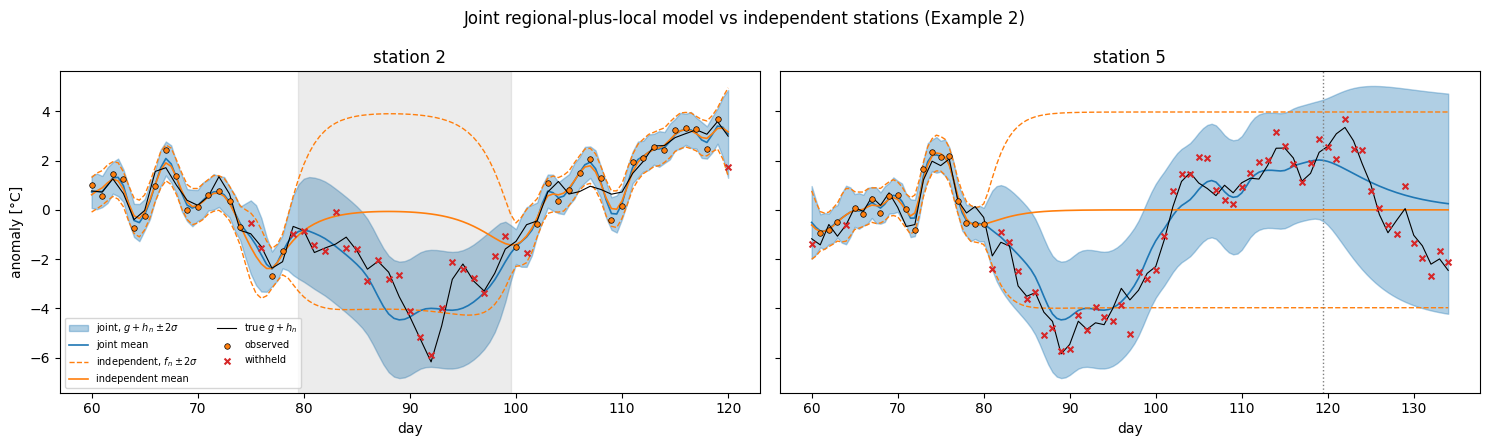

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5), sharey=True)
for ax, n, (lo, hi) in zip(axes, (1, 4), ((60, 120), (60, 134)), strict=True):
    win = (t_grid >= lo) & (t_grid <= hi)
    dwin = (np.asarray(days) >= lo) & (np.asarray(days) <= hi)
    ax.fill_between(
        t_grid[win],
        (total_mean[:, n] - 2 * total_sd[:, n])[win],
        (total_mean[:, n] + 2 * total_sd[:, n])[win],
        color="C0",
        alpha=0.35,
        label=r"joint, $g + h_n$ $\pm 2\sigma$",
    )
    ax.plot(t_grid[win], total_mean[win, n], "C0", lw=1.2, label="joint mean")
    ax.plot(
        t_grid[win],
        (ind_mean[:, n] - 2 * ind_f_sd[:, n])[win],
        "C1--",
        lw=1,
        label=r"independent, $f_n$ $\pm 2\sigma$",
    )
    ax.plot(t_grid[win], (ind_mean[:, n] + 2 * ind_f_sd[:, n])[win], "C1--", lw=1)
    ax.plot(t_grid[win], ind_mean[win, n], "C1", lw=1.2, label="independent mean")
    ax.plot(days[dwin], signal_true[n][dwin], "k-", lw=0.8, label="true $g + h_n$")
    seen = reported_true[n] & dwin
    ax.scatter(
        days[seen],
        y_true[n][seen],
        c="C1",
        edgecolors="k",
        linewidths=0.5,
        s=16,
        zorder=5,
        label="observed",
    )
    missed = withheld_true[n] & dwin
    ax.scatter(
        days[missed],
        y_true[n][missed],
        marker="x",
        c="C3",
        s=18,
        zorder=5,
        label="withheld",
    )
    ax.set_title(f"station {n + 1}")
    ax.set_xlabel("day")
axes[0].axvspan(79.5, 99.5, color="grey", alpha=0.15)
axes[1].axvline(LAST_REPORT - 0.5, color="grey", ls=":", lw=1)
axes[0].set_ylabel("anomaly [°C]")
axes[0].legend(loc="lower left", fontsize=7, ncol=2)
fig.suptitle("Joint regional-plus-local model vs independent stations (Example 2)")
plt.tight_layout()
plt.show()

Inside the records the two models agree, with an RMSE of 0.77 and 0.79 °C on the isolated gaps, because a station's own neighbouring days pin its value down in either model. Away from a station's own data they differ a lot. During station 2's outage the independent model relaxes to zero within a few days, while the station's true anomaly goes down to −6 °C, so its RMSE is 2.63 °C against 1.11 °C for the joint model, and its band holds only 90 % of the withheld values. On the days outside a station's own record the RMSE is 2.74 against 1.08 °C, and the coverage of the independent band drops to 84.3 %. Its band has the right width for one day, but the days outside a record are not independent, and in a cold spell most of them miss on the same side. In the forecast neither model has data, and the two are close (1.48 against 1.61 °C).

## 8. Cost

Each NUTS leapfrog step costs one Kalman filter pass over the $T$ merged days with the $D_x$-dimensional joint state, plus its reverse-mode gradient, so $\mathcal{O}(T D_x^3)$ with $D_x = 2 + 2 N_\Omega$. Below we time one jitted log density and its gradient for networks of 1, 2, 5, 10 and 20 stations on the same merged grid, which we build by repeating this network's mask and records, and compare with Example 2's vmapped independent filters on the same number of stations.

In [21]:
def time_grad(n_rows, repeats=10):
    # Shapes: n_rows stations; T merged days; D_x = 2 + 2 n_rows; 5 log parameters
    copies = -(-n_rows // n_stations)
    # the network's mask and records, repeated to n_rows stations
    mask_rows = jnp.tile(grid_mask, (1, copies))[:, :n_rows]  # → (T, n_rows)
    y_rows = jnp.tile(y_grid, (1, copies))[:, :n_rows]  # → (T, n_rows)

    def neg_log_marginal(log_params):
        params = jnp.exp(log_params)  # → (5,)
        # today (pyrox_ssm)
        regional_sde = MaternSDE(params[0], params[1], order=1)
        # today (pyrox_ssm)
        local_sde = MaternSDE(params[2], params[3], order=1)
        # today (pyrox_ssm)
        network = SharedPlusSiteMarkovGP(regional_sde, local_sde, grid_times, mask_rows)
        # ℒ_NLL(θ) = −log p(Y ∣ θ)
        return -network.log_marginal(y_rows, params[4])

    # today (jax)
    # ℒ_NLL(θ) and ∇_θ ℒ_NLL, jitted once
    loss_and_grad = jax.jit(jax.value_and_grad(neg_log_marginal))
    log_params = jnp.log(jnp.array(list(truth.values())))  # → (5,)
    jax.block_until_ready(loss_and_grad(log_params))
    t0 = time.perf_counter()
    for _ in range(repeats):
        jax.block_until_ready(loss_and_grad(log_params))
    return (time.perf_counter() - t0) / repeats


def time_grad_independent(n_rows, repeats=10):
    # Shapes: n_rows stations; N padded steps; 3 log parameters
    copies = -(-n_rows // n_stations)
    t_rows = jnp.tile(padded_times, (copies, 1))[:n_rows]  # → (n_rows, N)
    y_rows = jnp.tile(padded_y, (copies, 1))[:n_rows]  # → (n_rows, N)
    o_rows = jnp.tile(padded_mask, (copies, 1))[:n_rows]  # → (n_rows, N)

    def neg_log_likelihood(log_params):
        params = jnp.exp(log_params)  # → (3,)
        # today (jax)
        per_station = jax.vmap(
            station_log_marginal, in_axes=(0, 0, 0, None, None, None)
        )
        log_marginals = per_station(  # (n_rows, N) → (n_rows,)
            t_rows, y_rows, o_rows, params[0], params[1], params[2]
        )
        # ℒ_NLL = −∑ₙ log p(y_n ∣ ·)
        return -einx.sum("n ->", log_marginals)

    # today (jax)
    loss_and_grad = jax.jit(jax.value_and_grad(neg_log_likelihood))
    log_params = jnp.log(jnp.array([5.0, 4.0, 0.25]))  # → (3,)
    jax.block_until_ready(loss_and_grad(log_params))
    t0 = time.perf_counter()
    for _ in range(repeats):
        jax.block_until_ready(loss_and_grad(log_params))
    return (time.perf_counter() - t0) / repeats


print(f"{'stations':>9}{'D_x':>6}{'joint, ms':>12}{'independent, ms':>18}")
for rows in (1, 2, 5, 10, 20):
    joint_ms = 1e3 * time_grad(rows)
    independent_ms = 1e3 * time_grad_independent(rows)
    print(f"{rows:>9}{2 + 2 * rows:>6}{joint_ms:>12.2f}{independent_ms:>18.2f}")
print()
print(
    f"joint NUTS      : {nuts_seconds:6.1f} s  "
    f"(2 chains x 400 iterations, {n_grad} leapfrog steps after warm-up)"
)
print(
    f"independent NUTS: {independent_seconds:6.1f} s  "
    f"(2 chains x 400 iterations, {n_grad_ind} leapfrog steps after warm-up)"
)
print(
    f"joint decomposition   : {pred_seconds:5.1f} s  "
    f"({N_DRAWS} draws x {t_dense.shape[0]} times, with JIT)"
)
print(
    f"independent prediction: {ind_pred_seconds:5.1f} s  "
    f"({n_stations} stations x {N_DRAWS} draws x {t_dense.shape[0]} times, with JIT)"
)

 stations   D_x   joint, ms   independent, ms


        1     4        3.71              2.68


        2     6        6.41              3.18


        5    12       12.00              4.43


       10    22       18.73              6.45


       20    42       43.73             11.06

joint NUTS      :   57.1 s  (2 chains x 400 iterations, 4076 leapfrog steps after warm-up)
independent NUTS:   18.6 s  (2 chains x 400 iterations, 1948 leapfrog steps after warm-up)
joint decomposition   :   4.0 s  (100 draws x 270 times, with JIT)
independent prediction:   3.5 s  (5 stations x 100 draws x 270 times, with JIT)


One log density and its gradient cost 12.00 ms for this network of five stations ($D_x = 12$), against 4.43 ms for Example 2's five independent filters, so the joint model costs 2.7 times as much per gradient. It also needs more gradients, 10.2 leapfrog steps per draw against 4.9, as its posterior has five parameters instead of three, and the joint fit took 57.1 s against 18.6 s. The decomposition of 100 draws on the 270-point grid took 4.0 s, including JIT compilation.

With growing networks the joint gradient went from 3.71 ms for one station ($D_x = 4$) to 43.73 ms for 20 stations ($D_x = 42$), while the independent filters went from 2.68 to 11.06 ms. Between 10 and 20 stations the joint time grew by a factor of 2.3, whereas $D_x^3$ grew by $(42/22)^3 \approx 7$, so at these sizes the fixed cost of each filter step still outweighs the $D_x^3$ term. We did not time networks beyond 20 stations. The docstring of `SharedPlusSiteMarkovGP` points to gaussx's mean-field Kalman filter, which ignores the posterior correlation between the regional and the local parts, and to an ensemble Kalman filter for the point where $D_x^3$ does dominate.

## Summary

- A regional signal plus one local signal per station is a plain NumPyro function: priors on two SDE kernels and the noise, `SharedPlusSiteMarkovGP` rebuilt on the merged grid that `from_sites` returns, and its `log_marginal` as one factor site. The log marginal equals the dense Gaussian over all 391 observed (day, station) pairs to a relative difference of 2.2e-16.
- The Kalman filter integrates out the regional path and every local path, so NUTS runs on five parameters. It recovered four of them within their 90 % intervals, and the local kernel much more tightly than the regional one, since every station sees its own local path but there is only one regional path.
- `decompose`, with the variances read from `as_lgssm(...).smooth(...)` and averaged over 100 NUTS draws, splits every station into its regional and local parts. The regional signal comes back with an RMSE of 0.47 °C and 97.5 % coverage over the reporting days.
- The shared signal is what fills a station's outage and the days outside its record. There the joint model's RMSE is 1.11 and 1.08 °C, against 2.63 and 2.74 °C for Example 2's independent stations, and its bands keep their coverage.
- Each gradient costs 12.00 ms for five stations ($D_x = 12$), 2.7 times Example 2's independent filters, and it grows with the number of stations because the joint state does. The fit took 57.1 s of NUTS on CPU.

The next example moves from a handful of stations to a spatial field, where the regional signal varies in space as well as in time. For the stations on their own see [Example 2](ssm_hierarchical_sites.ipynb), and for one station [Example 1](ssm_one_site.ipynb).